*Previous notebook: learning rate decay and the problem of local optima. — This notebook: applying the previous techniques: a baseline network vs an improved one (L2, dropout, augmentation, early stopping, LR decay) and their comparison.*

# Implement the techniques of the precedent notebook

Training a neural network involves more than just running gradient descent. Several techniques can dramatically affect how fast the network learns, how well it generalises to unseen data, and whether it gets stuck or diverges.

This notebook explores the most important ones using a **synthetic regression dataset** built from a combination of trigonometric and logarithmic functions with added Gaussian noise.

## 1. Synthetic Dataset

Import the required libraries:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Generate 1000 evenly-spaced points over $[0, 4\pi]$ and compute the target function:

$$y_{\text{true}}(x) = \sin(x) + 0.5\cos(2x) + 0.3\ln(x+1)$$

Then add Gaussian noise $\varepsilon \sim \mathcal{N}(0,\, 0.2^2)$ to simulate real-world measurements:

$$y_{\text{noisy}}(x) = y_{\text{true}}(x) + \varepsilon$$

In [2]:
np.random.seed(42)

x       = np.linspace(0, 4 * np.pi, 1000)
y_true  = np.sin(x) + 0.5 * np.cos(2 * x) + 0.3 * np.log(x + 1)
noise   = np.random.normal(0, 0.2, size=x.shape)
y_noisy = y_true + noise

df = pd.DataFrame({'x': x, 'y_true': y_true, 'y_noisy': y_noisy})
df.head()

,x,y_true,y_noisy
0,0.000000,0.500000,0.599343
1,0.012579,0.516171,0.488518
2,0.025158,0.531976,0.661514
3,0.037737,0.547417,0.852023
4,0.050316,0.562492,0.515662


## 2. Train / Validation / Test Split

In [3]:
from sklearn.model_selection import train_test_split

X = df[['x']].values
y = df['y_noisy'].values.reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val,   X_test,  y_val,  y_test  = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f'Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}')

Train: 700  |  Val: 150  |  Test: 150


## 3. Input Normalisation

In [4]:
# Use the training set statistics to normalize all sets
mu    = X_train.mean()
sigma = X_train.std()

X_train_n = (X_train - mu) / sigma
X_val_n   = (X_val   - mu) / sigma
X_test_n  = (X_test  - mu) / sigma

print(f'Train mean: {X_train_n.mean():.4f}  std: {X_train_n.std():.4f}')
print(f'Val mean: {X_val_n.mean():.4f}  std: {X_val_n.std():.4f}')
print(f'Test mean: {X_test_n.mean():.4f}  std: {X_test_n.std():.4f}')

Train mean: -0.0000  std: 1.0000
Val mean: 0.0408  std: 1.0207
Test mean: -0.0483  std: 1.0160


## 4. Perform He initialization

In [5]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    params = {}
    for i in range(1, len(layer_sizes)):
        fan_in = layer_sizes[i - 1]
        params[f'W{i}'] = np.random.randn(fan_in, layer_sizes[i]) * np.sqrt(2 / fan_in)
        params[f'b{i}'] = np.zeros((1, layer_sizes[i]))
    return params

layer_sizes = [1, 64, 128, 64, 1]
params = init_params(layer_sizes)
print({k: v.shape for k, v in params.items()})

{'W1': (1, 64), 'b1': (1, 64), 'W2': (64, 128), 'b2': (1, 128), 'W3': (128, 64), 'b3': (1, 64), 'W4': (64, 1), 'b4': (1, 1)}


## 5. Train baseline

In [6]:
def relu(z):      
    return np.maximum(0, z)

def relu_deriv(z):  
    return (z > 0).astype(float)

In [7]:
def forward(X, params):
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):        # hidden layers — ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                        # output layer — linear
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    
    return z, cache

In [8]:
def backward(y, y_hat, params, cache):
    m = y.shape[0]
    grads = {}
    n_layers = len(params) // 2
    delta = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'z{i-1}'])
            
    return grads

In [9]:
def update_params(params, grads, lr):
    for key in params:
        params[key] -= lr * grads['d' + key]
        
    return params

In [10]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

In [11]:
import time

def train(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)
        params       = update_params(params, grads, lr)
        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

In [12]:
params_base, tl_base, vl_base, t_base = train(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 64, 128, 64, 1], lr=1e-2, epochs=2000
)


Final train MSE: 0.2536  |  val MSE: 0.2196  |  time: 88.38s


## 6. Improved Network

Five techniques are layered on top of the baseline:

| Technique | Details |
|---|---|
| **L2 regularisation** | Adds $\frac{\lambda}{2m}\sum\|W\|_F^2$ to the cost; shrinks weights and reduces overfitting |
| **Dropout** | Randomly zeros hidden neurons with probability $1-p_{\text{keep}}$, then rescales survivors by $1/p_{\text{keep}}$ (inverted dropout) |
| **Data augmentation** | Adds small Gaussian noise to training inputs at every epoch, increasing effective dataset diversity |
| **Early stopping** | Monitors validation MSE; halts training and restores the best checkpoint when no improvement is seen for `patience` epochs |
| **LR decay** | $\alpha_t = \dfrac{\alpha_0}{1 + d\cdot t}$ — large updates early, fine-grained steps near convergence |

> **Architecture note** — Regularisation combats overfitting. A small network like `[1,32,32,1]` barely overfits the baseline, so stacking L2 + dropout + augmentation only pushes it into underfitting. The improved version uses `[1,64,128,64,1]`: large enough to overfit without regularisation, but the techniques keep it in check. Each regulariser is also intentionally mild (`λ=0.001`, `keep_prob=0.95`) — piling them all at full strength would recreate the same problem.

> **Why not log loss?** Binary cross-entropy is designed for *classification* (sigmoid outputs, binary labels). This is a regression task with continuous targets, so MSE remains the right loss. L2 regularisation is added directly to MSE to penalise large weights.


**Inverted dropout** zeroes each hidden unit with probability $1 - p_{\text{keep}}$, then scales surviving activations up by $1/p_{\text{keep}}$ so the expected activation magnitude is unchanged. No correction is needed at inference time.

In [13]:
def forward_dropout(X, params, keep_prob=0.95, training=True):
    """Forward pass with inverted dropout on hidden layers."""
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):            # hidden layers — ReLU + dropout
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        if training:
            mask = (np.random.rand(*a.shape) < keep_prob)
            a    = a * mask / keep_prob      # inverted dropout: scale up surviving units
            cache[f'mask{i}'] = mask
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                             # output layer — linear, no dropout
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    return z, cache


The regularised cost adds the squared Frobenius norm of every weight matrix:

$$J_{\text{reg}} = \underbrace{\frac{1}{m}\sum(y - \hat{y})^2}_{\text{MSE}} + \underbrace{\frac{\lambda}{2m}\sum_l \|W^{(l)}\|_F^2}_{\text{L2 penalty}}$$

Its gradient w.r.t. $W^{(l)}$ gets an extra $\frac{\lambda}{m}W^{(l)}$ term. The dropout mask is re-applied during the backward pass so the gradient only flows through neurons that were *active* in the forward pass.

In [14]:
def mse_l2(y, y_hat, params, lambd=0.001):
    """MSE + L2 weight penalty."""
    m        = y.shape[0]
    n_layers = len(params) // 2
    l2       = sum(np.sum(params[f'W{i}'] ** 2) for i in range(1, n_layers + 1))
    return np.mean((y - y_hat) ** 2) + (lambd / (2 * m)) * l2


def backward_l2_dropout(y, y_hat, params, cache, lambd=0.001, keep_prob=0.95):
    """Backward pass with L2 regularisation and inverted-dropout gradient."""
    m        = y.shape[0]
    grads    = {}
    n_layers = len(params) // 2
    delta    = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta + (lambd / m) * params[f'W{i}']
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T
            if f'mask{i-1}' in cache:          # propagate only through active neurons
                delta = delta * cache[f'mask{i-1}'] / keep_prob
            delta = delta * relu_deriv(cache[f'z{i-1}'])

    return grads


**Data augmentation** injects a fresh noise perturbation into the training inputs at every epoch. This is the 1-D analogue of random cropping/flipping in image tasks: the network never sees exactly the same training example twice, which implicitly regularises it.

**Early stopping** keeps a running checkpoint of the best weights and restores them at the end, so the returned model corresponds to the epoch with the lowest validation MSE.

In [15]:
def augment_data(X, noise_std=0.02):
    """Add Gaussian noise to training inputs (data augmentation)."""
    return X + np.random.normal(0, noise_std, size=X.shape)


def train_improved(X_tr, y_tr, X_v, y_v, layer_sizes,
                   lr0=1e-2, epochs=5000, seed=0,
                   lambd=0.001, keep_prob=0.95,
                   decay_rate=3e-4, patience=500,
                   noise_std=0.01):
    params      = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []
    best_val    = np.inf
    best_params = None
    wait        = 0

    start = time.time()
    for epoch in range(epochs):
        lr    = lr0 / (1 + decay_rate * epoch)           # ① LR decay
        X_aug = augment_data(X_tr, noise_std=noise_std)  # ② data augmentation

        # ③ forward with dropout  ④ backward with L2
        y_hat, cache = forward_dropout(X_aug, params, keep_prob=keep_prob, training=True)
        grads        = backward_l2_dropout(y_tr, y_hat, params, cache,
                                           lambd=lambd, keep_prob=keep_prob)
        params       = update_params(params, grads, lr)

        # Evaluate in inference mode (dropout disabled)
        y_hat_tr, _ = forward_dropout(X_tr, params, training=False)
        y_hat_v,  _ = forward_dropout(X_v,  params, training=False)
        train_loss.append(mse(y_tr, y_hat_tr))   # pure MSE — comparable to baseline
        vl = mse(y_v, y_hat_v)
        val_loss.append(vl)

        # ⑤ early stopping
        if vl < best_val - 1e-6:
            best_val    = vl
            best_params = {k: v.copy() for k, v in params.items()}
            wait        = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'Early stopping at epoch {epoch + 1}  '
                      f'(best val MSE: {best_val:.4f})')
                break

    elapsed = time.time() - start
    print(f'Final train loss: {train_loss[-1]:.4f}  |  '
          f'val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return best_params, train_loss, val_loss, elapsed


In [16]:
# Same architecture, same seed — only regularisation differs.
# Key lessons from tuning:
#  • keep_prob=0.95 (very light dropout: enough signal, less noise on val)
#  • decay_rate=3e-4 (slow decay so LR is still useful at epoch 3000+)
#  • patience=500    (dropout makes val loss noisy — need more patience)
#  • epochs=5000     (model hadn't fully converged at 2000 epochs)
params_imp, tl_imp, vl_imp, t_imp = train_improved(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 64, 128, 64, 1],
    lr0=1e-2,    epochs=5000,
    lambd=0.001, keep_prob=0.95,
    decay_rate=3e-4, patience=500,
    noise_std=0.01, seed=0
)


Final train loss: 0.1904  |  val MSE: 0.1591  |  time: 210.57s


## 7. Comparison: Baseline vs Improved

Both models share the same architecture `[1, 64, 128, 64, 1]` and seed.
The differences are in the **training procedure**:

| | Baseline | Improved |
|---|---|---|
| Learning rate | constant 0.01 | decaying: $\alpha_0/(1+d\cdot t)$ |
| Regularisation | none | L2 + dropout + augmentation |
| Max epochs | 2000 | 5000 (early stopping) |
| Returned model | last epoch | best val checkpoint |

> The improvement comes from the **full pipeline** — better optimisation (LR decay, more epochs)
> combined with regularisation. The loss curves both track **pure MSE** on the same scale.


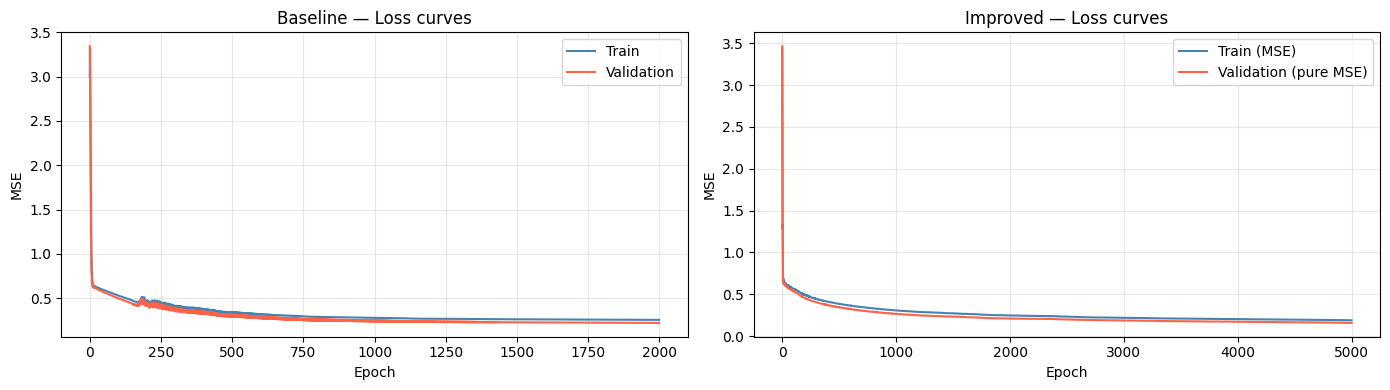

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(tl_base, color='steelblue', label='Train')
axes[0].plot(vl_base, color='tomato',    label='Validation')
axes[0].set_title('Baseline — Loss curves')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(tl_imp, color='steelblue', label='Train (MSE)')
axes[1].plot(vl_imp, color='tomato',    label='Validation (pure MSE)')
axes[1].set_title('Improved — Loss curves')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Test MSE  →  Baseline : 0.2641
Test MSE  →  Improved : 0.1991
Improvement           : 24.6%


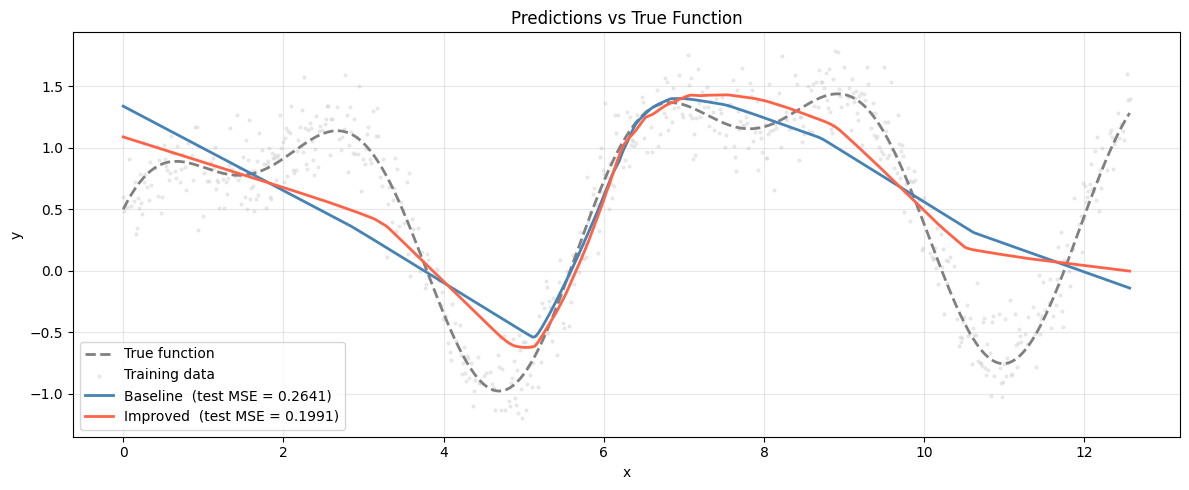

In [18]:
# Test-set evaluation
y_hat_base_test, _ = forward(X_test_n, params_base)
y_hat_imp_test,  _ = forward_dropout(X_test_n, params_imp, training=False)

test_mse_base = mse(y_test, y_hat_base_test)
test_mse_imp  = mse(y_test, y_hat_imp_test)

print(f'Test MSE  →  Baseline : {test_mse_base:.4f}')
print(f'Test MSE  →  Improved : {test_mse_imp:.4f}')
print(f'Improvement           : {(test_mse_base - test_mse_imp) / test_mse_base * 100:.1f}%')

# Prediction curves over the full input range
X_plot_n    = np.linspace(X_train_n.min(), X_train_n.max(), 500).reshape(-1, 1)
X_plot      = X_plot_n * sigma + mu          # denormalise for the x-axis

y_pred_base = forward(X_plot_n, params_base)[0]
y_pred_imp  = forward_dropout(X_plot_n, params_imp, training=False)[0]
y_true_plot = np.sin(X_plot) + 0.5 * np.cos(2 * X_plot) + 0.3 * np.log(X_plot + 1)

plt.figure(figsize=(12, 5))
plt.plot(X_plot, y_true_plot,
         color='gray', linewidth=2, linestyle='--', label='True function')
plt.scatter(X_train, y_train,
            color='lightgray', s=4, alpha=0.4, label='Training data')
plt.plot(X_plot, y_pred_base,
         color='steelblue', linewidth=2,
         label=f'Baseline  (test MSE = {test_mse_base:.4f})')
plt.plot(X_plot, y_pred_imp,
         color='tomato', linewidth=2,
         label=f'Improved  (test MSE = {test_mse_imp:.4f})')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Predictions vs True Function')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


In [19]:
def regression_report(name, y_true, y_pred, params=None):
    mse_val  = np.mean((y_true - y_pred) ** 2)
    rmse_val = np.sqrt(mse_val)
    mae_val  = np.mean(np.abs(y_true - y_pred))
    ss_res   = np.sum((y_true - y_pred) ** 2)
    ss_tot   = np.sum((y_true - y_true.mean()) ** 2)
    r2_val   = 1 - ss_res / ss_tot
    print(f'{name:10s} | MSE={mse_val:.4f}  RMSE={rmse_val:.4f}  MAE={mae_val:.4f}  R²={r2_val:.4f}')

regression_report('Baseline', y_test, y_hat_base_test)
regression_report('Improved', y_test, y_hat_imp_test)

Baseline   | MSE=0.2641  RMSE=0.5139  MAE=0.4139  R²=0.5292
Improved   | MSE=0.1991  RMSE=0.4462  MAE=0.3531  R²=0.6449


> **R² is particularly useful here** because it tells you how much of the signal the model can explain relative to the Gaussian noise — an R² close to $1 - \sigma^2 / \text{Var}(y_{\text{true}})$ would be the maximum theoretical value achievable given the noise you added.

In [20]:
# Theoretical R² ceiling: the best any model can achieve given the noise level.
# A perfect model would predict y_true exactly; its residuals would be pure noise (σ² = 0.2²).
# R²_max = 1 - σ² / Var(y_true)
noise_std = 0.2
r2_max = 1 - noise_std**2 / np.var(y_true)
print(f'Theoretical R² max: {r2_max:.4f}')

Theoretical R² max: 0.9272
